Title

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# Setting parameters
Duration_Threshold = 1440
International_Stations = ["Luik", "Düsseldorf", "Aachen", "Brussel", "Liège"]

# Filtering the data
Disruption_Data = pd.read_csv('data/disruptions-2025.csv')

# Long_Disruptions = Disruption_Data[Disruption_Data["duration_minutes"] > Duration_Threshold]

National_Connections = Disruption_Data.copy()

for station in International_Stations:
    National_Connections = National_Connections[~National_Connections["ns_lines"].str.contains(station)]

Long_Disruptions = National_Connections.copy()

Long_Disruptions = National_Connections[National_Connections["duration_minutes"] > Duration_Threshold]



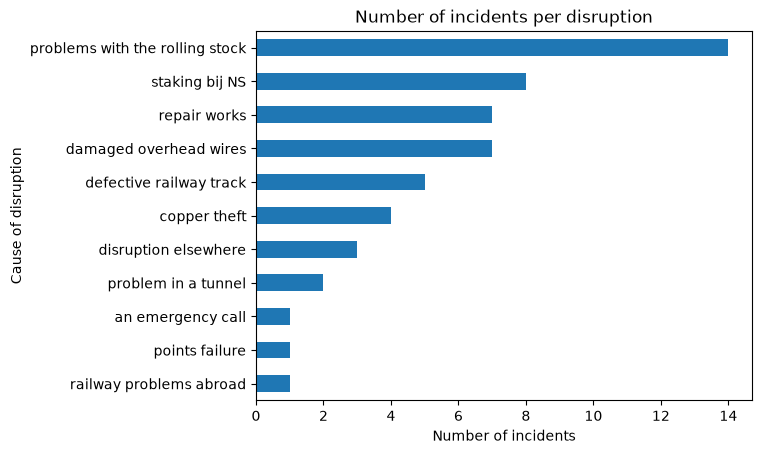

In [7]:
# Visualizing the number of incidents per disruption
Cause_Count = Long_Disruptions["cause_en"].value_counts()
Cause_Count.sort_values().plot(kind="barh")
plt.xlabel("Number of incidents")
plt.ylabel("Cause of disruption")
plt.title("Number of incidents per disruption")
plt.show()

In [18]:
Longest_10_Disruptions = National_Connections.sort_values(by="duration_minutes", ascending=False).head(30)
display(Longest_10_Disruptions[["duration_minutes", "ns_lines", "cause_en", "start_time", "rdt_lines"]])

,duration_minutes,ns_lines,cause_en,start_time,rdt_lines
490,13234.0,Heerlen - Maastricht,problems with the rolling stock,2025-01-23 03:47:16,Heerlen - Maastricht
5586,10876.0,Utrecht - Eindhoven,repair works,2025-10-30 11:14:42,'s-Hertogenbosch - Utrecht Centraal
4141,8300.0,Heerlen - Maastricht Randwyck,problems with the rolling stock,2025-08-12 06:51:14,Heerlen - Maastricht
4537,8244.0,Heerlen - Maastricht,problems with the rolling stock,2025-09-04 07:03:31,Heerlen - Maastricht
4232,8144.0,Hengelo - Bielefeld,problems with the rolling stock,2025-08-18 05:47:57,"Berlin Ostbahnhof - Hengelo, Bielefeld Hbf - H..."
677,6614.0,Heerlen - Maastricht,problems with the rolling stock,2025-02-01 09:51:44,Heerlen - Maastricht
393,5479.0,Heerlen - Maastricht Randwyck,problems with the rolling stock,2025-01-18 05:26:21,Heerlen - Maastricht
5644,5463.0,Schiphol - Utrecht,repair works,2025-11-03 03:57:17,"Amsterdam Centraal - Utrecht Centraal, Schipho..."
2959,4557.0,Dordrecht - Roosendaal,repair works,2025-06-06 22:08:18,Dordrecht - Roosendaal
4773,4378.0,Heerlen - Maastricht,problems with the rolling stock,2025-09-16 08:42:06,Heerlen - Maastricht


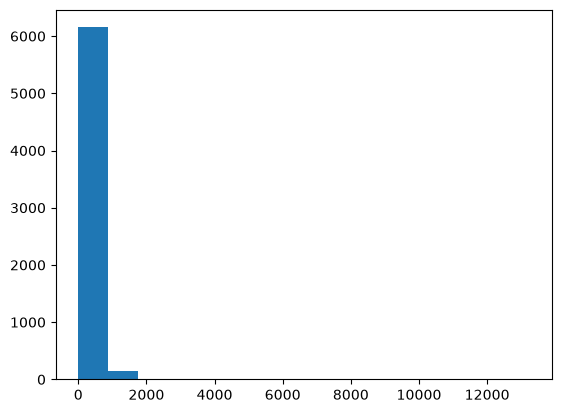

In [13]:
# plt.plot(National_Connections["duration_minutes"])
plt.hist(National_Connections["duration_minutes"], bins=15);

# plt.plot(National_Connections["duration_minutes"])

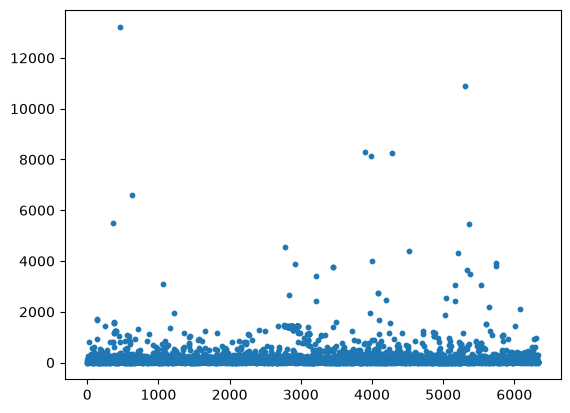

In [14]:
plt.scatter(
    range(len(National_Connections)),
    National_Connections["duration_minutes"],
    s=10
)

(0.0, 500.0)

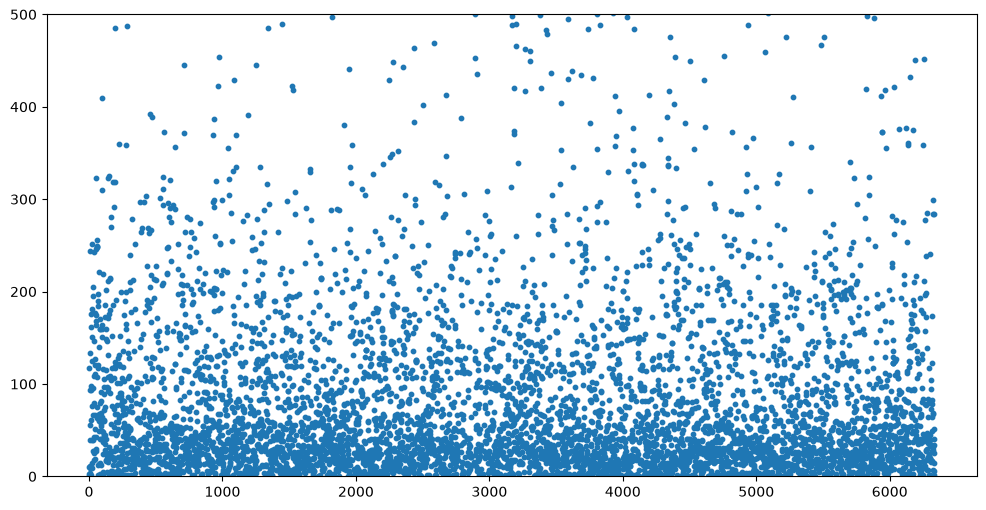

In [16]:
plt.figure(figsize=(12, 6))

plt.scatter(
    range(len(National_Connections)),
    National_Connections["duration_minutes"],
    s=10
)

plt.ylim(0, 500)

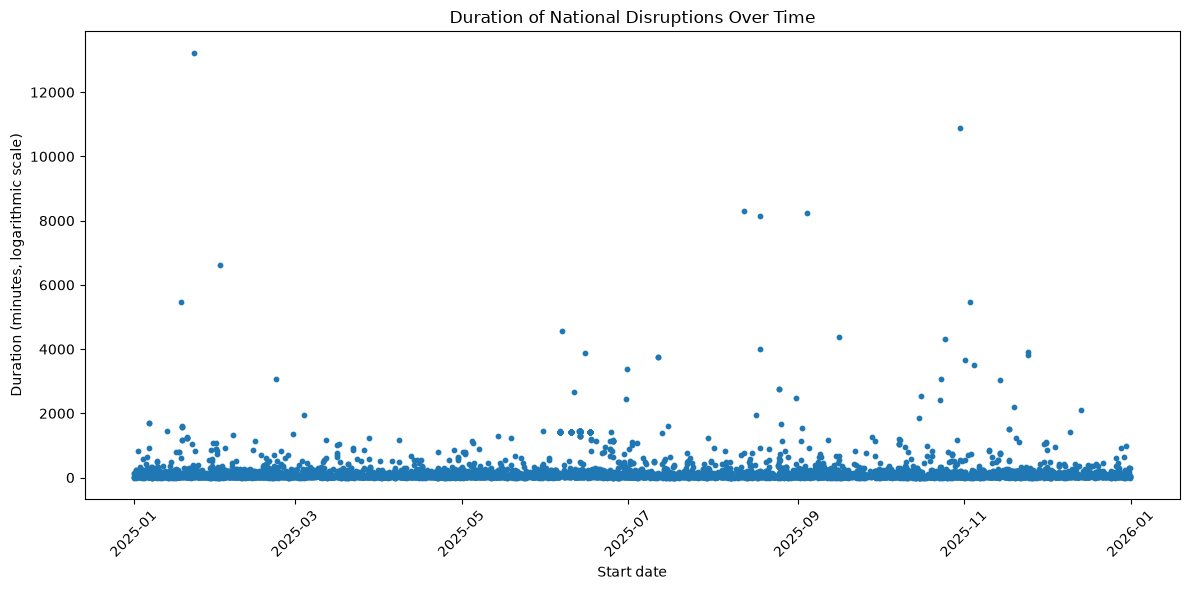

In [ ]:
# Convert start_time to datetime
National_Connections["start_time"] = pd.to_datetime(
    National_Connections["start_time"]
)

# Plot duration against start date
plt.figure(figsize=(12, 6))

plt.scatter(
    National_Connections["start_time"],
    National_Connections["duration_minutes"],
    s=10
)

# plt.yscale("log")
plt.xlabel("Start date")
plt.ylabel("Duration (minutes)")
plt.title("Duration of National Disruptions Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Hello